In [5]:
import pandas as pd
import numpy as np

df = pd.read_parquet("/Users/emilsvigants/Projects/aesthetic-unsplash-image-analysis/data/ava_cleaned_features.parquet")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Dataset shape: (20420, 7)
Columns: ['image_id', 'mean_score', 'std_score', 'total_votes', 'rating_counts', 'structural_features', 'clip_embedding']


,image_id,mean_score,std_score,total_votes,rating_counts,structural_features,clip_embedding
0,111875,5.807692,1.670312,208,"[1, 2, 7, 34, 53, 50, 28, 19, 7, 7]","[0.08417275547981262, 0.15377438068389893, 1.2...","[0.0016924834344536066, -0.014361293986439705,..."
1,287132,4.852174,1.671986,230,"[7, 12, 22, 52, 63, 42, 19, 8, 3, 2]","[0.043213702738285065, 0.04941313713788986, 1....","[-0.0006810238119214773, 0.012423894368112087,..."
2,712748,4.763514,1.275346,148,"[1, 5, 17, 33, 54, 29, 6, 2, 1, 0]","[0.4837675094604492, 0.31897664070129395, 1.02...","[0.0030595441348850727, 0.027914635837078094, ..."
3,60556,5.918239,1.504578,159,"[0, 3, 5, 14, 41, 43, 34, 11, 5, 3]","[0.48542794585227966, 0.24875479936599731, 0.9...","[0.041529785841703415, 0.01705673150718212, -0..."
4,522313,5.065089,1.192392,169,"[2, 1, 5, 39, 74, 33, 10, 3, 1, 1]","[0.4340306222438812, 0.19774529337882996, 0.97...","[-0.019383734092116356, 0.0010034549050033092,..."


In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# 1. Unpack the lists stored in the DataFrame cells into flat 2D matrices
clip_matrix = np.vstack(df['clip_embedding'].values)
struct_matrix = np.vstack(df['structural_features'].values)
std_matrix = df[['std_score']].to_numpy(dtype=np.float32)

# 2. Combine them horizontally into one massive numerical matrix
X_raw = np.hstack((clip_matrix, struct_matrix, std_matrix))
print(f"Final extracted matrix shape: {X_raw.shape}")

# 3. Standardize features (zero mean, unit variance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 4. Apply PCA (aligning with Emils & Imola's PCA step)
n_components = min(20, X_scaled.shape[1])
pca = PCA(n_components=n_components, random_state=42)
X_features = pca.fit_transform(X_scaled)
print(f"Explained variance by {n_components} components: {np.sum(pca.explained_variance_ratio_):.2%}")

Final extracted matrix shape: (20420, 525)
Explained variance by 20 components: 26.76%


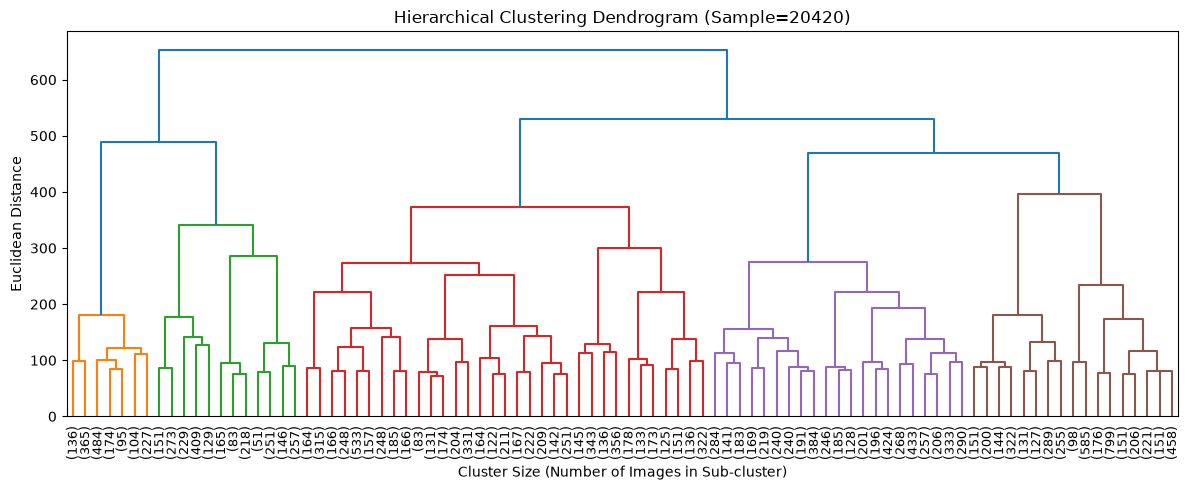

In [8]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
import numpy as np

np.random.seed(42)
size=X_features.shape[0]
sample_size = min(size, X_features.shape[0])
sample_idx = np.random.choice(X_features.shape[0], sample_size, replace=False)
X_sample = X_features[sample_idx]

plt.figure(figsize=(12, 5))
Z = linkage(X_sample[:size], method='ward')
dendrogram(Z, truncate_mode='lastp', p=90, leaf_rotation=90., leaf_font_size=9.)
plt.title(f"Hierarchical Clustering Dendrogram (Sample={sample_size})")
plt.xlabel("Cluster Size (Number of Images in Sub-cluster)")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.savefig("hierarchical_dendrogram.png", dpi=300)
plt.show()

In [9]:
from scipy.spatial.distance import cdist
from sklearn.metrics import davies_bouldin_score, silhouette_score
import pandas as pd

def run_cure_clustering(X_all, X_samp, samp_indices, n_clusters=8, n_reps=5, alpha=0.2):
    hc = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')
    samp_labels = hc.fit_predict(X_samp)

    representatives = []
    rep_cluster_labels = []

    for c_id in range(n_clusters):
        mask = (samp_labels == c_id)
        cluster_pts = X_samp[mask]
        centroid = np.mean(cluster_pts, axis=0)

        chosen_pts = []
        for _ in range(min(n_reps, len(cluster_pts))):
            if not chosen_pts:
                dists = np.linalg.norm(cluster_pts - centroid, axis=1)
                idx = np.argmax(dists)
            else:
                dists = np.min(cdist(cluster_pts, np.array(chosen_pts)), axis=1)
                idx = np.argmax(dists)

            chosen_pts.append(cluster_pts[idx])
            shrunk_pt = cluster_pts[idx] + alpha * (centroid - cluster_pts[idx])
            representatives.append(shrunk_pt)
            rep_cluster_labels.append(c_id)

    representatives = np.array(representatives)
    rep_cluster_labels = np.array(rep_cluster_labels)

    all_dists = cdist(X_all, representatives, metric='euclidean')
    full_labels = rep_cluster_labels[np.argmin(all_dists, axis=1)]
    return full_labels

results = []
for k in [5, 8, 10, 12]:
    labels = run_cure_clustering(X_features, X_sample, sample_idx, n_clusters=k)
    db_idx = davies_bouldin_score(X_features, labels)
    sil = silhouette_score(X_features, labels, sample_size=min(5000, X_features.shape[0]), random_state=42)
    results.append({"k": k, "Davies-Bouldin (Lower=Better)": db_idx, "Silhouette (Higher=Better)": sil})

df_eval = pd.DataFrame(results)
print(df_eval)

    k  Davies-Bouldin (Lower=Better)  Silhouette (Higher=Better)
0   5                       4.314465                    0.018705
1   8                       3.842642                    0.020930
2  10                       3.769489                    0.010875
3  12                       4.295520                   -0.000433


In [11]:
best_idx = df_eval["Davies-Bouldin (Lower=Better)"].idxmin()
best_k = int(df_eval.loc[best_idx, "k"])
print(f"Automatically selected optimal clusters (k): {best_k}")

df["cure_cluster"] = run_cure_clustering(X_features, X_sample, sample_idx, n_clusters=best_k)

cluster_profile = df.groupby("cure_cluster")[['mean_score']].mean()
print("Cluster Profiles (Aesthetic Score):")
print(cluster_profile)

def find_top_similar_in_cluster(query_idx, top_k=5):
    c_id = df.loc[query_idx, "cure_cluster"]
    cluster_rows = df[df["cure_cluster"] == c_id].index.to_numpy()
    dists = cdist(X_features[query_idx:query_idx+1], X_features[cluster_rows], metric='euclidean').flatten()
    nearest_local = np.argsort(dists)[1:top_k+1]
    return df.iloc[cluster_rows[nearest_local]][['image_id', 'mean_score', 'cure_cluster']]

print("\nTop similar images to row 0 within its cluster:")
print(find_top_similar_in_cluster(0))

Automatically selected optimal clusters (k): 10
Cluster Profiles (Aesthetic Score):
              mean_score
cure_cluster            
0               5.152601
1               5.561034
2               5.454412
3               5.359713
4               5.570507
5               5.282809
6               5.442971
7               5.344180
8               5.469027
9               5.284180

Top similar images to row 0 within its cluster:
      image_id  mean_score  cure_cluster
15407   115834    4.795455             8
14490   812897    4.985075             8
853     744375    5.111940             8
18031    49388    6.248980             8
8047    130683    3.593137             8


In [12]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.spatial.distance import cdist
import numpy as np

np.random.seed(42)
kf = KFold(n_splits=2, shuffle=True, random_state=42)
y_true = df['mean_score'].to_numpy()

cure_rmses, kmeans_rmses = [], []
# Scale the sample size proportionally for the half-sized training fold
fold_sample_size = min(max(1, sample_size // 2), len(X_features) // 2)

for train_idx, test_idx in kf.split(X_features):
    X_tr, X_te = X_features[train_idx], X_features[test_idx]
    y_tr, y_te = y_true[train_idx], y_true[test_idx]

    # --- 1. CURE Evaluation (Dynamic sample_size and best_k) ---
    samp_idx = np.random.choice(len(X_tr), fold_sample_size, replace=False)
    hc = AgglomerativeClustering(n_clusters=best_k, metric='euclidean', linkage='ward')
    tr_labels = hc.fit_predict(X_tr[samp_idx])

    reps, rep_labels = [], []
    for c_id in range(best_k):
        mask = (tr_labels == c_id)
        cluster_pts = X_tr[samp_idx][mask]
        if len(cluster_pts) == 0:
            continue
        centroid = np.mean(cluster_pts, axis=0)
        chosen_pts = []
        for _ in range(min(5, len(cluster_pts))):
            if not chosen_pts:
                dists = np.linalg.norm(cluster_pts - centroid, axis=1)
                idx = np.argmax(dists)
            else:
                dists = np.min(cdist(cluster_pts, np.array(chosen_pts)), axis=1)
                idx = np.argmax(dists)
            chosen_pts.append(cluster_pts[idx])
            reps.append(cluster_pts[idx] + 0.2 * (centroid - cluster_pts[idx]))
            rep_labels.append(c_id)

    reps = np.array(reps)
    rep_labels = np.array(rep_labels)

    tr_assigned = rep_labels[np.argmin(cdist(X_tr, reps), axis=1)]
    cure_cluster_means = {c: y_tr[tr_assigned == c].mean() for c in range(best_k)}
    test_rep_labels = rep_labels[np.argmin(cdist(X_te, reps), axis=1)]
    y_pred_cure = np.array([cure_cluster_means.get(c, y_tr.mean()) for c in test_rep_labels])
    cure_rmses.append(np.sqrt(mean_squared_error(y_te, y_pred_cure)))

    # --- 2. K-Means Evaluation (Dynamic best_k) ---
    km = KMeans(n_clusters=best_k, random_state=42, n_init=5).fit(X_tr)
    km_cluster_means = {c: y_tr[km.labels_ == c].mean() for c in range(best_k)}
    test_km_labels = km.predict(X_te)
    y_pred_km = np.array([km_cluster_means.get(c, y_tr.mean()) for c in test_km_labels])
    kmeans_rmses.append(np.sqrt(mean_squared_error(y_te, y_pred_km)))

print(f"Configuration -> Sample Size: {sample_size} (Fold Sample: {fold_sample_size}) | Best k: {best_k}")
print(f"CURE (k={best_k}) 2-Fold CV RMSE:    {np.mean(cure_rmses):.4f}")
print(f"K-Means (k={best_k}) 2-Fold CV RMSE: {np.mean(kmeans_rmses):.4f}")

Configuration -> Sample Size: 20420 (Fold Sample: 10210) | Best k: 10
CURE (k=10) 2-Fold CV RMSE:    0.7215
K-Means (k=10) 2-Fold CV RMSE: 0.7149


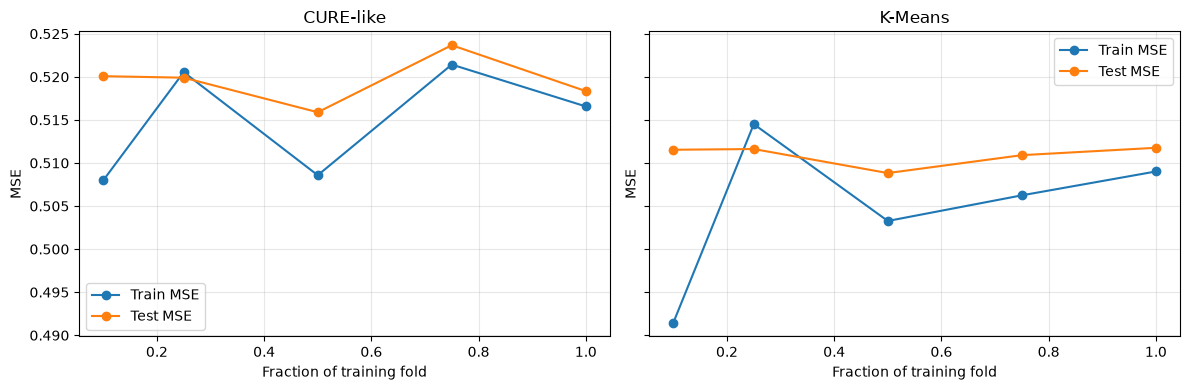

Mean scores across folds:
   method  fraction  train_mse  test_mse  test_rmse
CURE-like      0.10   0.507985  0.520072   0.721152
CURE-like      0.25   0.520540  0.519898   0.721039
CURE-like      0.50   0.508575  0.515887   0.718248
CURE-like      0.75   0.521420  0.523668   0.723645
CURE-like      1.00   0.516562  0.518340   0.719953
  K-Means      0.10   0.491469  0.511534   0.715216
  K-Means      0.25   0.514507  0.511616   0.715270
  K-Means      0.50   0.503268  0.508828   0.713318
  K-Means      0.75   0.506242  0.510906   0.714773
  K-Means      1.00   0.509011  0.511760   0.715372


: 

In [ ]:
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import mean_squared_error
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

y = df["mean_score"].to_numpy()
fractions = [0.1, 0.25, 0.5, 0.75, 1.0]
kf = KFold(n_splits=2, shuffle=True, random_state=42)
records = []

def cure_predict(X_train, X_test, k, rng, sample_cap=2000):
    """Fit the notebook's CURE-like method and assign train/test rows."""
    n_sample = min(len(X_train), sample_cap)
    sample = X_train[rng.choice(len(X_train), n_sample, replace=False)]
    labels = AgglomerativeClustering(
        n_clusters=k, metric="euclidean", linkage="ward"
    ).fit_predict(sample)

    reps, rep_labels = [], []
    for cluster in range(k):
        points = sample[labels == cluster]
        centroid = points.mean(axis=0)
        chosen = []
        for _ in range(min(5, len(points))):
            if not chosen:
                distances = np.linalg.norm(points - centroid, axis=1)
            else:
                distances = cdist(points, points[chosen]).min(axis=1)
                distances[chosen] = -np.inf
            idx = np.argmax(distances)
            chosen.append(idx)
            reps.append(points[idx] + 0.2 * (centroid - points[idx]))
            rep_labels.append(cluster)

    reps = np.asarray(reps)
    rep_labels = np.asarray(rep_labels)
    return (
        rep_labels[cdist(X_train, reps).argmin(axis=1)],
        rep_labels[cdist(X_test, reps).argmin(axis=1)],
    )

def score_predictions(train_labels, test_labels, y_train, y_test):
    means = {
        label: y_train[train_labels == label].mean()
        for label in np.unique(train_labels)
    }
    fallback = y_train.mean()
    train_pred = np.array([means.get(label, fallback) for label in train_labels])
    test_pred = np.array([means.get(label, fallback) for label in test_labels])
    return mean_squared_error(y_train, train_pred), mean_squared_error(y_test, test_pred)

for fold, (train_idx, test_idx) in enumerate(kf.split(X_raw), start=1):
    rng = np.random.default_rng(42 + fold)
    shuffled_train = rng.permutation(train_idx)

    for fraction in fractions:
        n_train = max(best_k, int(len(train_idx) * fraction))
        if n_train > len(train_idx):
            raise ValueError("Training fold is smaller than best_k.")
        subset = shuffled_train[:n_train]

        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_raw[subset])
        X_test_scaled = scaler.transform(X_raw[test_idx])

        pca = PCA(n_components=min(20, *X_train_scaled.shape), random_state=42)
        X_train = pca.fit_transform(X_train_scaled)
        X_test = pca.transform(X_test_scaled)
        y_train, y_test = y[subset], y[test_idx]

        cure_train, cure_test = cure_predict(X_train, X_test, best_k, rng)
        km = KMeans(n_clusters=best_k, random_state=42, n_init=5).fit(X_train)

        for method, train_labels, test_labels in [
            ("CURE-like", cure_train, cure_test),
            ("K-Means", km.labels_, km.predict(X_test)),
        ]:
            train_mse, test_mse = score_predictions(
                train_labels, test_labels, y_train, y_test
            )
            records.append({
                "fold": fold, "fraction": fraction, "method": method,
                "train_mse": train_mse, "test_mse": test_mse,
                "test_rmse": np.sqrt(test_mse),
            })

scores = pd.DataFrame(records)
summary = scores.groupby(["method", "fraction"], as_index=False)[
    ["train_mse", "test_mse", "test_rmse"]
].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, method in zip(axes, ["CURE-like", "K-Means"]):
    data = summary[summary["method"] == method]
    ax.plot(data["fraction"], data["train_mse"], "o-", label="Train MSE")
    ax.plot(data["fraction"], data["test_mse"], "o-", label="Test MSE")
    ax.set(title=method, xlabel="Fraction of training fold", ylabel="MSE")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

print("Mean scores across folds:")
print(summary.to_string(index=False))